# Contactome Weight Distributions

This standalone notebook loads every contactome graph CSV from `data/graphs/contactomes`, summarizes their edge weights, and visualizes the combined weight distributions. Run the cells top-to-bottom to regenerate the tables and plots.

In [1]:
from pathlib import Path
import csv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("ggplot")


def find_repo_root(marker: str = "pyproject.toml") -> Path:
    """Walk up from the present directory until the repository marker is found."""
    current = Path().resolve()
    for candidate in (current, *current.parents):
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate {marker!r} starting from {current}")


REPO_ROOT = find_repo_root()
CONTACTOME_DIR = REPO_ROOT / "data" / "graphs" / "contactomes"

if not CONTACTOME_DIR.exists():
    raise FileNotFoundError(f"Expected contactome directory at {CONTACTOME_DIR}")

CONTACTOME_DIR


PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes')

In [2]:
csv_paths = sorted(CONTACTOME_DIR.glob("contactome-*5.csv"))
if not csv_paths:
    raise FileNotFoundError(f"No contactome CSV files found in {CONTACTOME_DIR}")

print(f"Found {len(csv_paths)} contactome CSV files.")
csv_paths[:5]


Found 10 contactome CSV files.


[PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes/contactome-0k-100825.csv'),
 PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes/contactome-10k-100825.csv'),
 PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes/contactome-15k-100825.csv'),
 PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes/contactome-20k-100825.csv'),
 PosixPath('/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/data/graphs/contactomes/contactome-25k-100825.csv')]

In [3]:
def parse_contactome_metadata(path: Path) -> tuple[str, str]:
    tail = path.stem[len("contactome-") :]
    parts = tail.split("-", 1)
    stage = parts[0]
    variant = parts[1] if len(parts) > 1 else "raw"
    return stage, variant


def stage_sort_value(stage: str) -> int:
    digits = "".join(ch for ch in stage if ch.isdigit())
    return int(digits) if digits else 0


def read_contactome_weights(path: Path) -> list[int]:
    weights: list[int] = []
    with path.open(newline="") as handle:
        reader = csv.reader(handle)
        next(reader, None)  # skip header
        for row in reader:
            if len(row) < 3:
                continue
            try:
                weights.append(int(row[2]))
            except ValueError:
                continue
    return weights


metadata = {path: parse_contactome_metadata(path) for path in csv_paths}
stage_order = sorted({stage for stage, _ in metadata.values()}, key=stage_sort_value)
variant_order = sorted({variant for _, variant in metadata.values()})

records: list[dict] = []
for path in csv_paths:
    stage, variant = metadata[path]
    for weight in read_contactome_weights(path):
        records.append({
            "weight": weight,
            "stage": stage,
            "variant": variant,
            "graph": path.stem,
        })

weights = pd.DataFrame.from_records(records)
weights["stage"] = pd.Categorical(weights["stage"], categories=stage_order, ordered=True)
weights["variant"] = pd.Categorical(weights["variant"], categories=variant_order, ordered=True)

print(f"Loaded {len(weights):,} edges across {len(csv_paths)} contactome graphs.")
weights.head()


Loaded 76,890,682 edges across 10 contactome graphs.


,weight,stage,variant,graph
0,134784,0k,100825,contactome-0k-100825
1,92448,0k,100825,contactome-0k-100825
2,23328,0k,100825,contactome-0k-100825
3,35424,0k,100825,contactome-0k-100825
4,146016,0k,100825,contactome-0k-100825


In [4]:
summary = (
    weights.groupby(["variant", "stage"])["weight"]
    .agg(
        count="size",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
        pct_90=lambda s: s.quantile(0.9),
        pct_99=lambda s: s.quantile(0.99),
    )
    .round(2)
)
summary


/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_41732/2444976195.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  weights.groupby(["variant", "stage"])["weight"]


count       mean   median         std   min         max  \
variant stage                                                              
100825  0k     7883274  115819.20  33696.0  1157114.69  5184  1357152192   
        5k     7760360  115835.65  33696.0  1166074.53  5184  1360234944   
        10k    7739790  116105.36  33696.0  1170442.29  5184  1360234944   
        15k    7713987  116431.69  33696.0  1172016.40  5184  1360234944   
        20k    7689777  116777.69  33696.0  1174976.51  5184  1360234944   
        25k    7666177  117117.67  33696.0  1177637.87  5184  1360234944   
        30k    7641559  117475.17  33696.0  1179985.28  5184  1360234944   
        35k    7619942  117751.72  33696.0  1179554.46  5184  1360234944   
        40k    7595953  118018.38  33696.0  1175100.52  5184  1360234944   
        45k    7579863  118257.72  33696.0  1176752.08  5184  1360234944   

                 pct_90     pct_99  
variant stage                       
100825  0k     232416.0  1151712.0  
        5k     231552.0  1149120.0  
        10k    231552.0  1156032.0  
        15k    231552.0  1164672.0  
        20k    231552.0  1174176.0  
        25k    231552.0  1181952.0  
        30k    231552.0  1191456.0  
        35k    231552.0  1200096.0  
        40k    231552.0  1208736.0  
        45k    231552.0  1215648.0

In [5]:
coverage_target = 0.90

total_weight = weights["weight"].sum()
if total_weight <= 0:
    raise ValueError("Total weight must be positive to compute coverage threshold.")

sorted_weights = (
    weights[["weight"]]
    .sort_values("weight", ascending=False)
    .reset_index(drop=True)
)

cumulative_share = sorted_weights["weight"].cumsum() / total_weight
cutoff_index = int(np.searchsorted(cumulative_share.to_numpy(), coverage_target))
if cutoff_index >= len(sorted_weights):
    cutoff_index = len(sorted_weights) - 1

coverage_threshold = sorted_weights.loc[cutoff_index, "weight"]

retained_mask = weights["weight"] >= coverage_threshold
retained_edges = retained_mask.sum()
retained_share = retained_edges / len(weights)
retained_weight_share = weights.loc[retained_mask, "weight"].sum() / total_weight

print(f"{coverage_target:.0%} coverage threshold: {coverage_threshold:,} nm^2")
print(f"Edges retained: {retained_edges:,} ({retained_share:.4%} of edges)")
print(f"Weight retained: {retained_weight_share:.4%} of total weight")

coverage_threshold


90% coverage threshold: 49,248 nm^2
Edges retained: 30,049,010 (39.0802% of edges)
Weight retained: 90.0088% of total weight


np.int64(49248)

/var/folders/1z/9cg7xdn56bl0jc6kbnbvddvh0000gn/T/ipykernel_36948/2384516575.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for variant, group in weights.groupby("variant"):


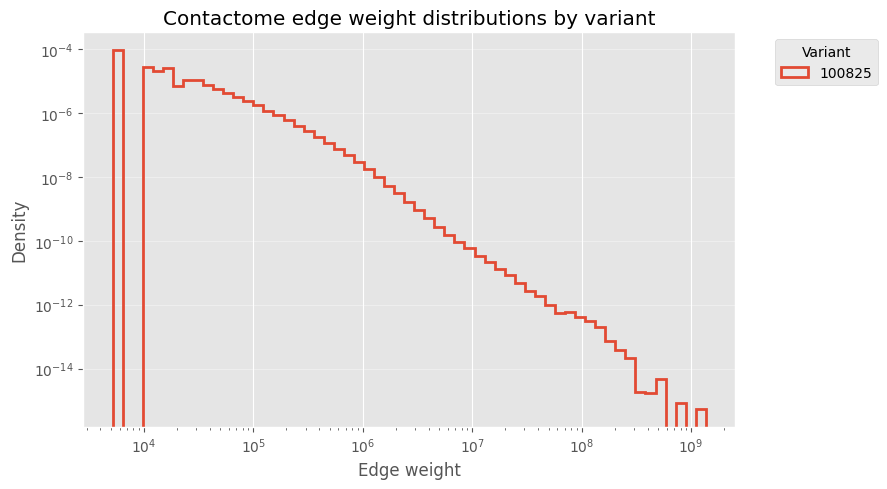

In [7]:
positive_weights = weights.loc[weights["weight"] > 0, "weight"]
if positive_weights.empty:
    raise ValueError("All weights are non-positive; log-scale histogram cannot be created.")

bins = np.logspace(np.log10(positive_weights.min()), np.log10(positive_weights.max()), 60)

fig, ax = plt.subplots(figsize=(9, 5))
for variant, group in weights.groupby("variant"):
    ax.hist(
        group.loc[group["weight"] > 0, "weight"],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2.0,
        label=variant,
    )

ax.set_xscale("log")
ax.set_xlabel("Edge weight")
ax.set_ylabel("Density")
ax.set_title("Contactome edge weight distributions by variant")
ax.legend(title="Variant", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(True, which="both", axis="y", alpha=0.35)
plt.yscale("log")
plt.tight_layout()
